# Sri Lankan Dengue Case Prediction Using Machine Learning
**Applied Machine Learning - M.Sc. in Artificial Intelligence, University of Moratuwa**

Notebook walk-through of the full workflow. The same code runs non-interactively via
`python scripts/run_pipeline.py`; all logic lives in `src/dengue/` so the notebook stays readable.

**Contents**
1. Problem statement and objective
2. Dataset source and data dictionary
3. Initial inspection, data-quality checks and EDA
4. Cleaning and preprocessing (feature engineering)
5. Validation strategy (rolling-origin, time-ordered)
6. Baselines and candidate models
7. Model comparison and selected model
8. SHAP and LIME explanations
9. Forward forecast, conclusions and limitations

## 1. Problem statement and objective
Dengue is one of Sri Lanka's most significant public-health problems; notified cases vary strongly
between the 26 Regional Director of Health Services (RDHS) divisions and from week to week.

**Objective:** predict the number of dengue cases notified in each RDHS division **in the following week**
(one-week-ahead forecast) from the surveillance data available at the end of the current week, and compare
machine-learning models against simple forecasting baselines.

**Who would use it:** RDHS / MOH teams planning vector-control campaigns and hospital bed / staff allocation.
A useful forecast must beat "next week will look like this week" (the persistence baseline).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from dengue import config
from dengue.data import load_raw, load_about, build_tables, quality_report
from dengue.features import build_supervised
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = config.FIGURES; RES = config.RESULTS

## 2. Dataset source and data dictionary
* **Source:** Epidemiology Unit, Ministry of Health, Sri Lanka - *Weekly Epidemiological Report*, Table 1
  (cases notified by Medical Officers of Health, by RDHS division). <https://www.epid.gov.lk/weekly-epidemiological-report/weekly-epidemiological-report>
* **Compiled as:** dataset `disease-surveillance`, version 2026-10-10, by research.dulajmendis.com
  (<https://research.dulajmendis.com/data/disease-surveillance/>), downloaded as Excel.
* **Licence:** none stated; the Epidemiology Unit asks to be acknowledged as the primary data source.
* **Unit of observation (raw):** one value for one *(week-ending date, indicator)*; the indicator names the disease,
  the measure and the place.

The workbook's own metadata sheet:

In [2]:
about = load_about()
about[about.field.isin(["Title","Description","Definition","Coverage","Source","Licence","Cite as","Release note"])]

,field,value
0,Title,Dengue and leptospirosis
1,Description,Dengue and leptospirosis cases notified each w...
2,Definition,Cases notified by Medical Officers of Health t...
6,Coverage,"2023-12-29 to 2026-08-16, weekly, LK"
8,Source,"Epidemiology Unit, Ministry of Health: Weekly ..."
9,Licence,"Epidemiology Unit, Ministry of Health: no lice..."
10,Cite as,"Epidemiology Unit, Ministry of Health, Sri Lan..."
15,Release note,First release. Dengue and leptospirosis cases ...


In [3]:
raw = load_raw()
print(raw.shape)
raw.head()

(1242, 10)


,date,indicator,value,unit,geography,status,source,disease,measure,place
0,2026-06-14,"Dengue, cases notified in the week: Ampara RDHS",2,cases,LK,unflagged,epid-weekly-epidemiological-report,dengue,week,Ampara RDHS
1,2026-06-21,"Dengue, cases notified in the week: Ampara RDHS",32,cases,LK,unflagged,epid-weekly-epidemiological-report,dengue,week,Ampara RDHS
2,2026-06-28,"Dengue, cases notified in the week: Ampara RDHS",32,cases,LK,unflagged,epid-weekly-epidemiological-report,dengue,week,Ampara RDHS
3,2026-07-05,"Dengue, cases notified in the week: Ampara RDHS",56,cases,LK,unflagged,epid-weekly-epidemiological-report,dengue,week,Ampara RDHS
4,2026-07-12,"Dengue, cases notified in the week: Ampara RDHS",64,cases,LK,unflagged,epid-weekly-epidemiological-report,dengue,week,Ampara RDHS


| Raw column | Meaning |
|---|---|
| `date` | last day of the reporting week (for full-year totals: last day of week 52) |
| `indicator` | `"<Disease>, <measure>: <place>"` - parsed into `disease`, `measure`, `place` |
| `value` | number of notified cases (integer) |
| `unit` / `geography` / `status` / `source` | constant: `cases` / `LK` / `unflagged` / source record id |

| Parsed measure | Meaning | Coverage |
|---|---|---|
| `week` | cases notified in that week | 2026 weeks 24-33 (10 weeks, 14 Jun - 16 Aug 2026) |
| `ytd` | cumulative cases in 2026 up to that week | same 10 weeks |
| `full_year` | cases in weeks 1-52 | 2023, 2024, 2025 |

Places: 26 RDHS divisions (district boundaries, with Ampara district split into Ampara and Kalmunai) + the national total *Sri Lanka*.

In [4]:
raw.groupby(["disease","measure"]).agg(rows=("value","size"), first=("date","min"), last=("date","max"), places=("place","nunique"))

rows      first       last  places
disease       measure                                      
dengue        full_year    81 2023-12-29 2025-12-26      27
              week        270 2026-06-14 2026-08-16      27
              ytd         270 2026-06-14 2026-08-16      27
leptospirosis full_year    81 2023-12-29 2025-12-26      27
              week        270 2026-06-14 2026-08-16      27
              ytd         270 2026-06-14 2026-08-16      27

## 3. Initial inspection, data-quality checks and EDA

In [5]:
data = build_tables(raw)
q = quality_report(data)
print(json.dumps({k: v for k, v in q["overview"].items() if k != "weekly_dates"}, indent=1))
display(q["national_sum_check"]); display(q["ytd_consistency_check"])

{
 "rows": 1242,
 "indicators": 162,
 "places": 27,
 "divisions_excl_national": 26,
 "full_year_dates": [
  "2023-12-29",
  "2024-12-27",
  "2025-12-26"
 ],
 "missing_values": 0,
 "duplicate_rows": 0,
 "negative_values": 0,
 "status_values": {
  "unflagged": 1242
 }
}


,series,max_abs_gap_divisions_vs_national
0,dengue_week,0
1,dengue_ytd,0
2,leptospirosis_week,0
3,leptospirosis_ytd,0


,disease,max_abs_gap_ytd_increment_vs_week
0,dengue,0
1,leptospirosis,0


The table is complete (no missing, duplicate or negative values), divisions sum exactly to the national total
and every year-to-date figure equals the previous one plus the week's cases. The *internal arithmetic* is therefore sound.
The next check looks at whether the **pattern across divisions** is consistent from one week to the next.

In [6]:
q['adjacent_week_correlation']

,week_a,week_b,pearson_r_log_cases,identical_in_all_divisions
0,2026-06-14,2026-06-21,0.039,False
1,2026-06-21,2026-06-28,1.000,True
2,2026-06-28,2026-07-05,0.983,False
3,2026-07-05,2026-07-12,0.972,False
4,2026-07-12,2026-07-19,0.977,False
5,2026-07-19,2026-07-26,0.975,False
6,2026-07-26,2026-08-02,0.982,False
7,2026-08-02,2026-08-09,0.980,False
8,2026-08-09,2026-08-16,0.947,False


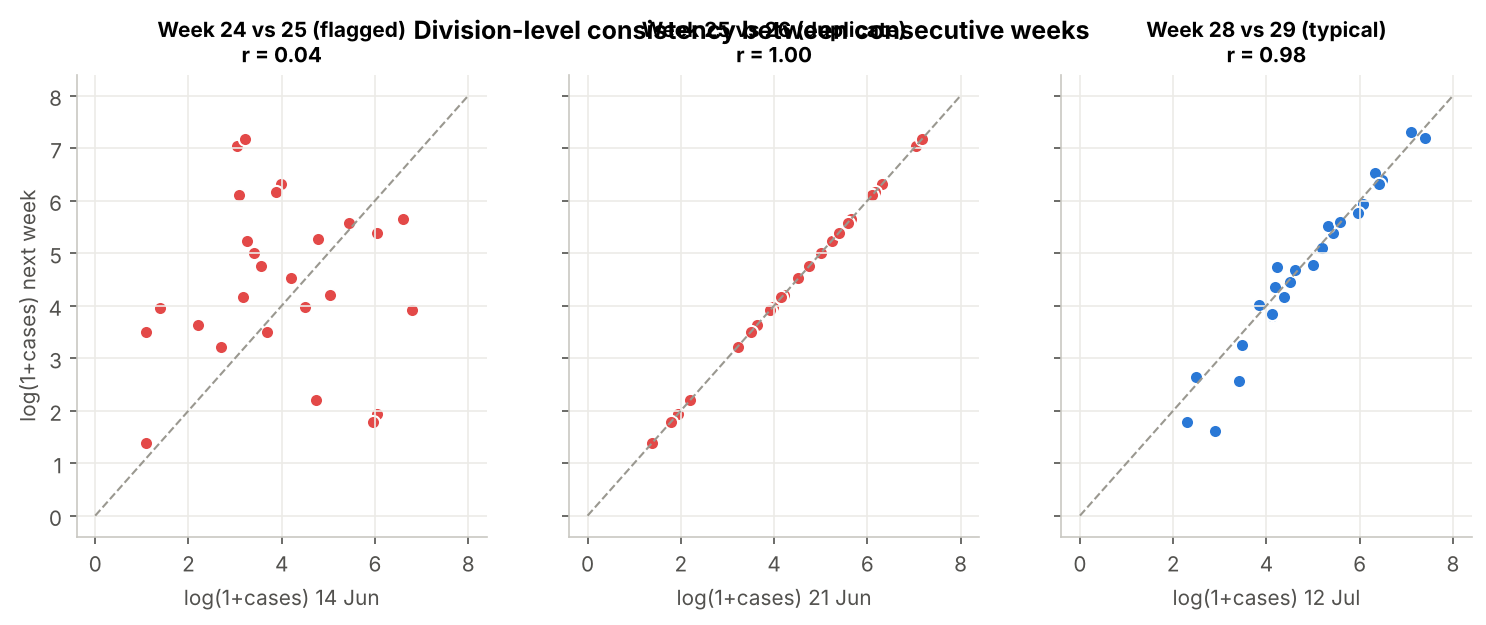

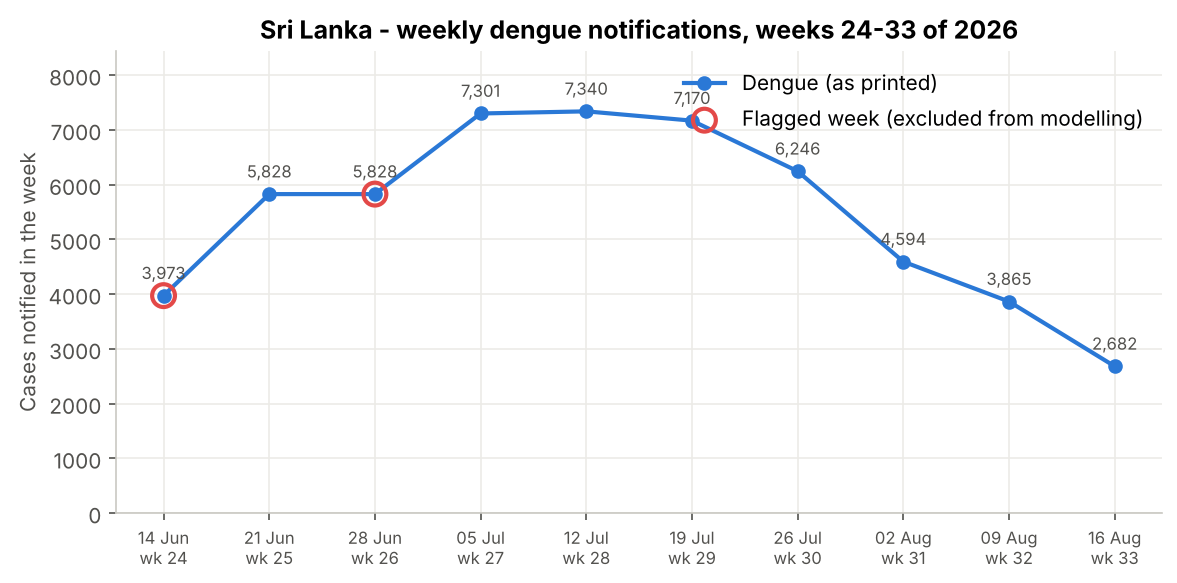

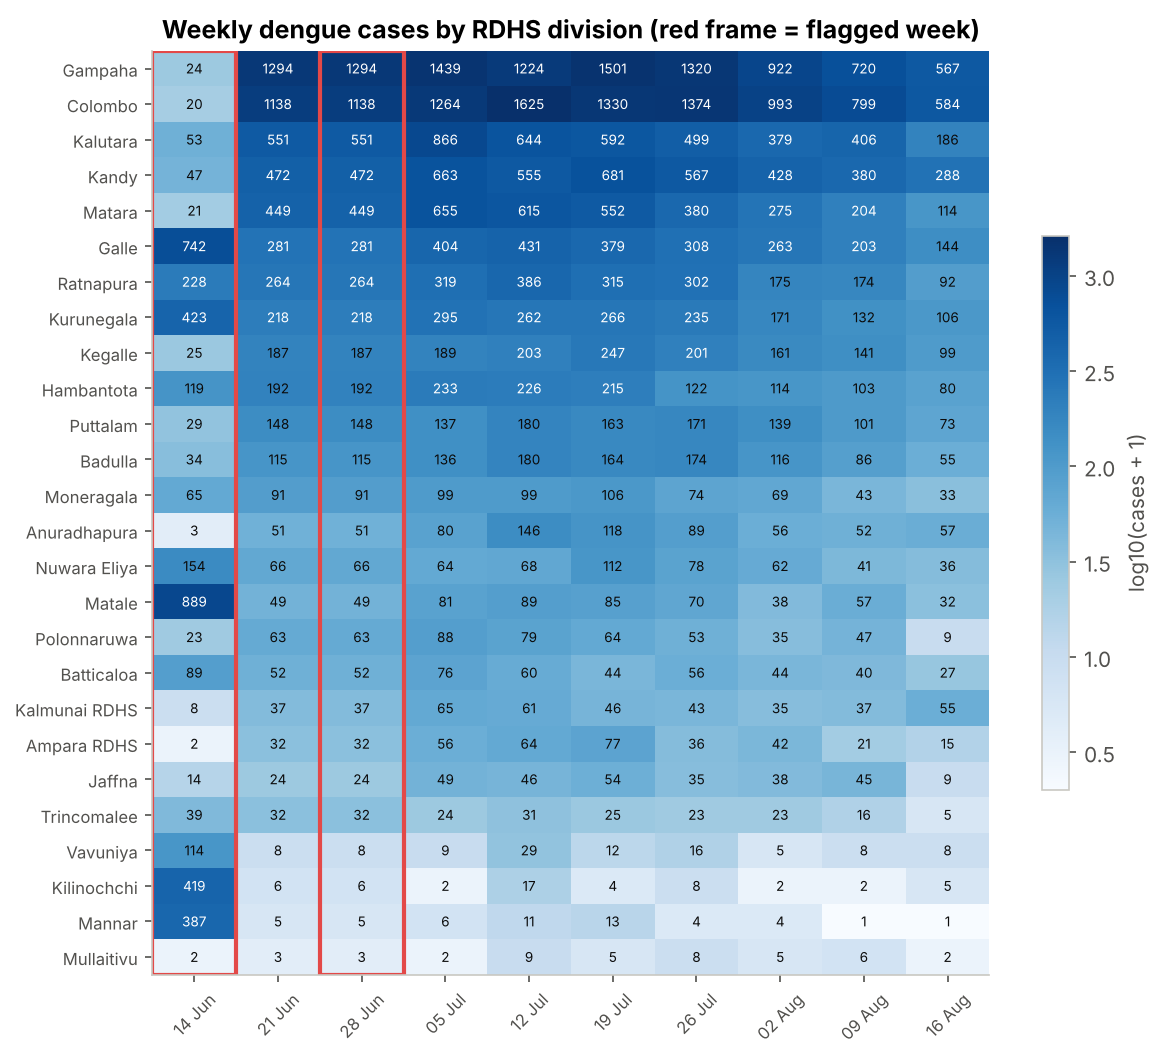

In [7]:
for f in ['04_week_consistency_diagnostic.png', '01_national_weekly_trend.png', '02_division_heatmap.png']:
    display(Image(filename=str(FIG / f)))

**Two weeks are unreliable at division level and are excluded from modelling (kept in the raw data, not altered):**

* **Week 24 (ending 14 Jun 2026)** - the national total is plausible, but the division pattern has essentially no
  correlation with the following week (r = 0.04, versus r = 0.95-0.98 for every other pair of adjacent weeks).
  Colombo goes 20 -> 1,138 and Kilinochchi 419 -> 6. This is consistent with values being attached to the wrong
  divisions somewhere between the printed report and the compiled dataset; it cannot be corrected without the original PDF.
* **Week 26 (ending 28 Jun 2026)** - identical to week 25 in all 26 divisions. The dataset's own source note says
  Vol. 53 No. 27 re-printed week 25's dengue counts; the true week-26 counts are unknown.

**What the EDA shows**
* The 2026 mid-year season peaked in weeks 27-29 (~7,300 cases/week nationally) and declined steadily to 2,682 in week 33.
* Burden is highly concentrated: Colombo and Gampaha together account for ~40% of cases; Mullaitivu, Mannar and Kilinochchi
  report single digits. Counts therefore span three orders of magnitude -> models work on a **log scale**.
* Historical (2023-2025) totals rank the divisions almost the same way as 2026, so past burden is a useful scale feature.

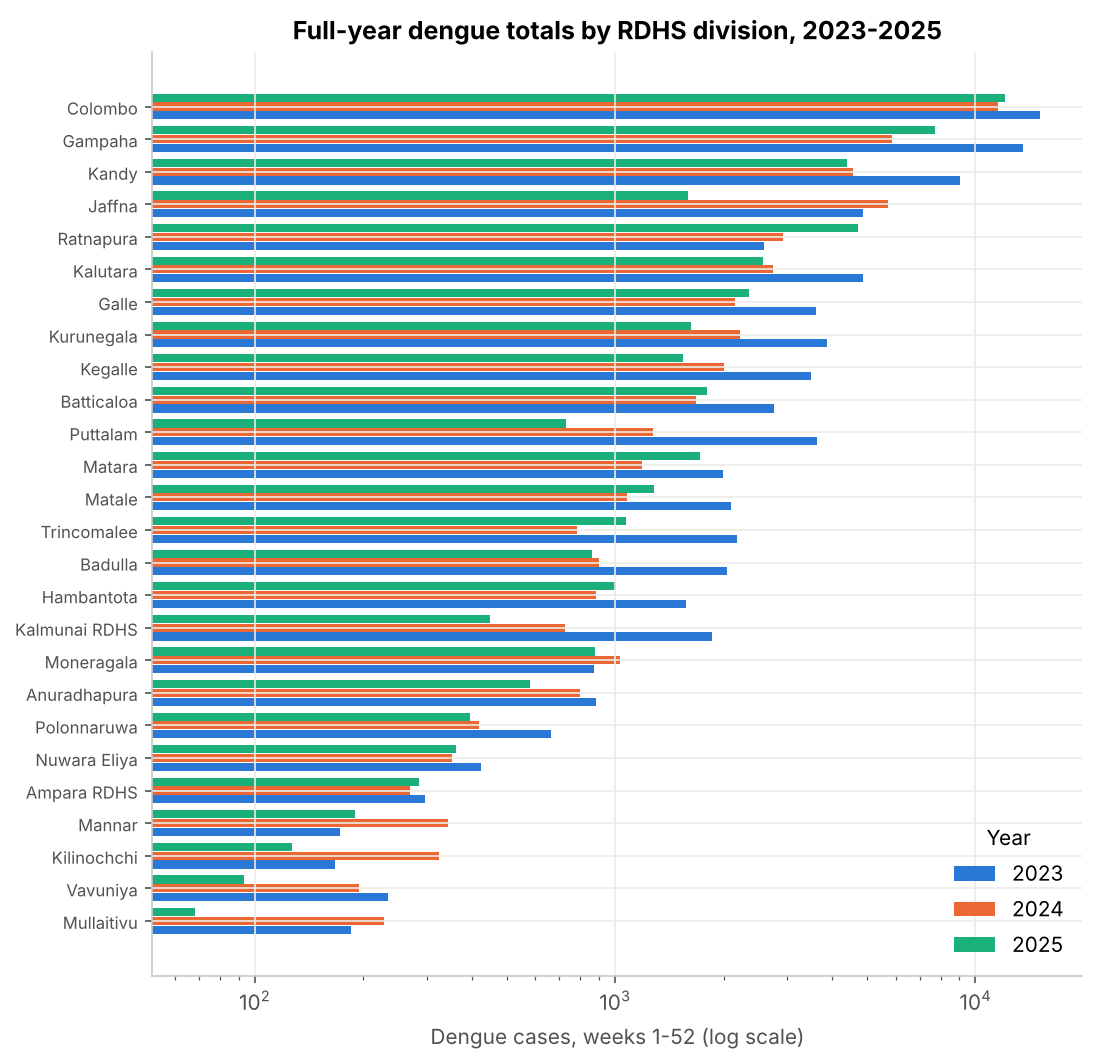

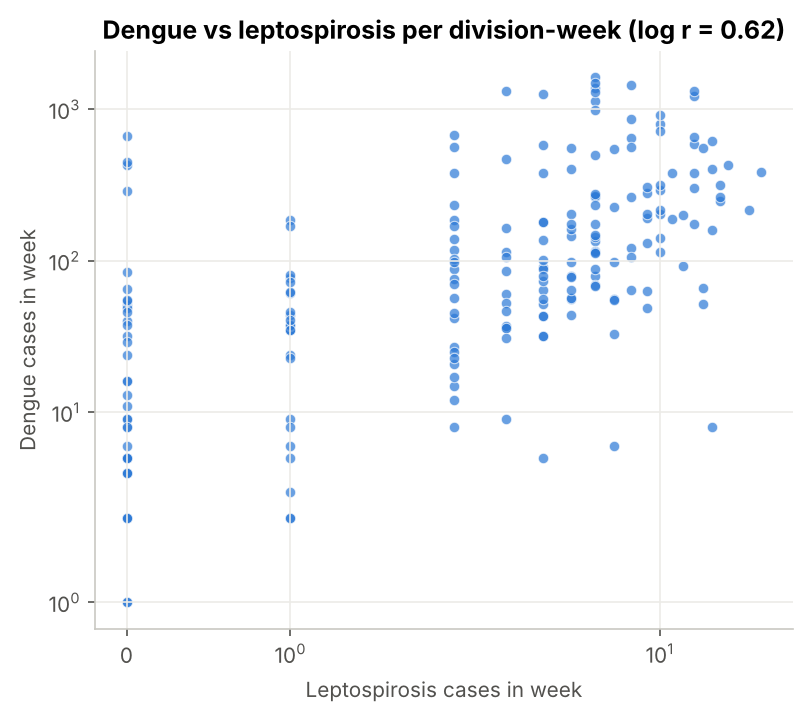

In [8]:
for f in ['03_annual_totals_by_division.png', '06_dengue_vs_leptospirosis.png']:
    display(Image(filename=str(FIG / f)))

Leptospirosis (also notified in Table 1) is moderately correlated with dengue across division-weeks (log r ~ 0.6), largely
because both are bigger in populous, wet-zone divisions. It is included as a candidate feature; the model decides whether it helps.

## 4. Cleaning and preprocessing - building the forecasting table
One row = one division at one **forecast origin week t**. Every feature is known at the end of week t (no leakage); the target is week t+1.

**Target:** `log1p(cases[t+1]) - log1p(cases[t])` (log growth). Predictions are converted back to counts with
`cases[t] * growth`. This makes the task scale-free across divisions, anchors every model to persistence, and lets
tree models (which cannot extrapolate) generalise from small to large divisions.

Rows exist only where both week t and t+1 are reliable: origins 5 Jul - 9 Aug 2026 -> **6 origins x 26 divisions = 156 rows**.
Where week t-1 is unavailable (origin 5 Jul, because week 26 is excluded) the one-week growth features are set to 0 (= no change).

In [9]:
sup = build_supervised(data)
display(pd.DataFrame.from_dict(config.FEATURE_DESCRIPTIONS, orient="index", columns=["description"]))
print(sup.shape); sup.origin_date.value_counts().sort_index()

,description
log_cases_t,log(1 + dengue cases notified in the current w...
growth_1w,log-growth from week t-1 to week t (0 if week ...
log_hist_weekly_mean,"log(1 + mean weekly cases, from the 2023-2025 ..."
intensity_vs_hist,log_cases_t minus log_hist_weekly_mean (how un...
log_ytd_weekly_rate,log(1 + 2026 year-to-date cases / epidemiologi...
cases_vs_ytd_rate,log_cases_t minus log_ytd_weekly_rate (above/b...
log_lepto_t,"log(1 + leptospirosis cases in week t), a co-r..."
national_growth_1w,log-growth of the Sri Lanka national dengue to...


(156, 16)


origin_date
2026-07-05    26
2026-07-12    26
2026-07-19    26
2026-07-26    26
2026-08-02    26
2026-08-09    26
Name: count, dtype: int64

In [10]:
sup[config.FEATURES + ['target_log_growth']].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
log_cases_t,156.0,4.524,1.519,0.693,3.732,4.500,5.579,7.394
growth_1w,156.0,-0.085,0.362,-1.281,-0.239,-0.064,0.019,1.792
log_hist_weekly_mean,156.0,3.269,1.112,1.407,2.349,3.338,3.969,5.519
intensity_vs_hist,156.0,1.255,0.849,-1.015,0.787,1.483,1.817,3.008
log_ytd_weekly_rate,156.0,3.972,1.128,1.215,3.179,3.852,5.003,6.327
cases_vs_ytd_rate,156.0,0.552,0.736,-2.176,0.201,0.649,1.076,1.749
log_lepto_t,156.0,1.413,0.876,0.000,0.693,1.609,1.979,3.135
national_growth_1w,156.0,-0.106,0.113,-0.307,-0.173,-0.081,0.000,0.005
target_log_growth,156.0,-0.151,0.425,-1.569,-0.319,-0.166,0.055,1.792


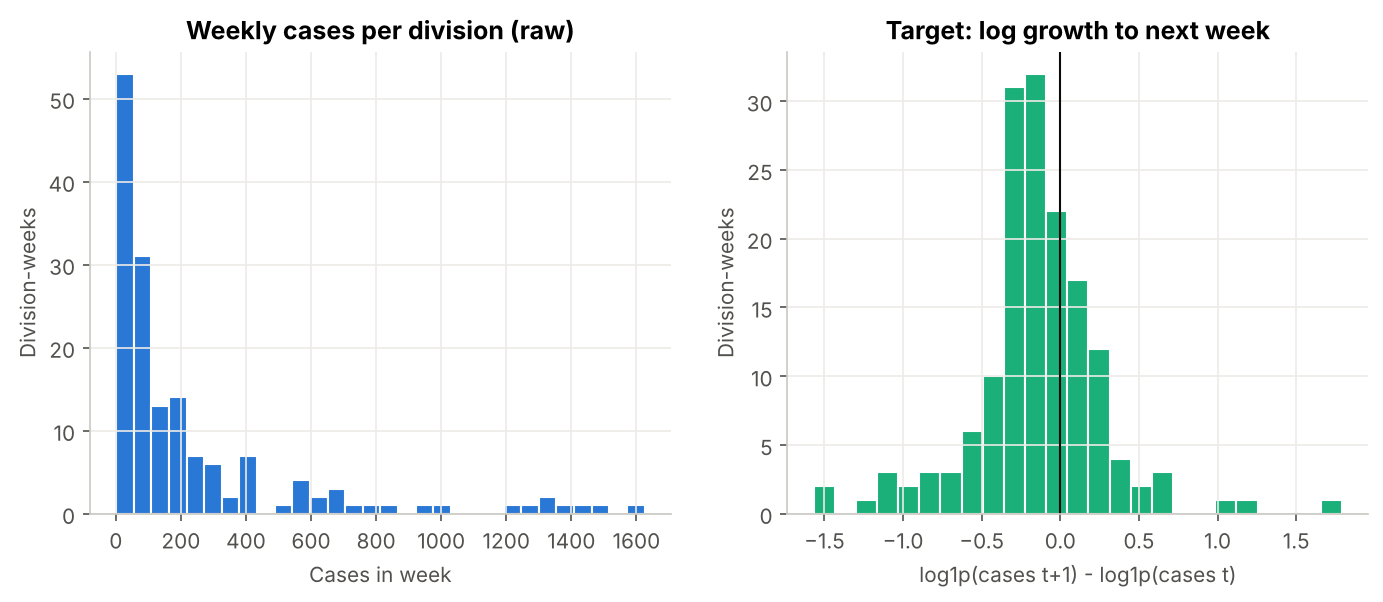

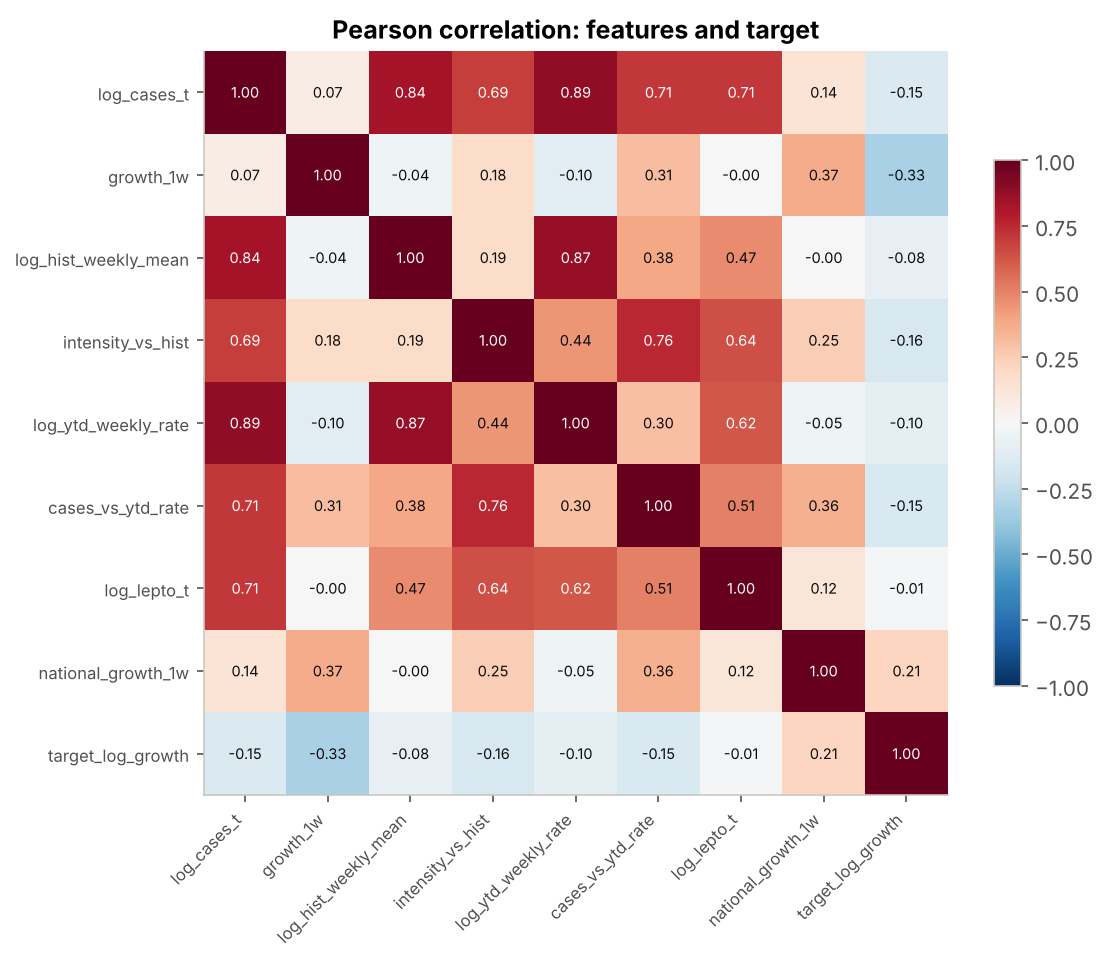

In [11]:
for f in ['05_distributions.png', '07_feature_correlation.png']:
    display(Image(filename=str(FIG / f)))

Several features are strongly inter-correlated (current cases, historical mean, YTD rate all measure *size*).
This does not hurt tree models' accuracy but **does** affect how SHAP/LIME share credit between them - see Section 8.
No single feature is strongly correlated with the target (|r| <= 0.33): next-week growth is hard to predict, which is why
the baselines are demanding.

## 5. Validation strategy
Data are time-ordered, so random K-fold would leak the future into training. A **rolling-origin (expanding-window)** design is used:

| Role | Forecast origins (week ending) | Forecast target weeks | Used for |
|---|---|---|---|
| Validation | 19 Jul, 26 Jul | weeks 30, 31 | hyper-parameter tuning + model selection |
| Test | 2 Aug, 9 Aug | weeks 32, 33 | final, untouched evaluation |

For each origin the model is re-trained on all *earlier* origins only (52-130 rows) and then forecasts all 26 divisions.

**Metrics** (case scale unless noted): MAE and RMSE (cases), WAPE (% of all cases), R^2, MAE on log scale (treats small
and large divisions equally), **skill vs persistence** = 1 - MAE/MAE_persistence, and the error of the summed national total.

## 6. Baselines and candidate models
| Model | Type | Why |
|---|---|---|
| Persistence | naive baseline | "next week = this week" - the standard forecasting reference |
| Moving average (2 wk) | naive baseline | smooths noise |
| National-trend naive | stronger baseline | this week x last week's national growth: tests whether ML beats simple trend-following |
| Ridge regression | linear benchmark | regularised linear model on standardised features |
| Random Forest | bagging ensemble | robust with few rows, captures interactions |
| XGBoost | gradient boosting | strong tabular learner, regularised |
| LightGBM | gradient boosting | leaf-wise boosting; shallow trees (4-8 leaves) suit tiny data |
| Ensemble (RF+XGB+LGBM) | averaging ensemble | reduces variance of individual learners |

Grids are deliberately small (2-12 settings) because the validation window is only 52 forecasts.
The cell below runs the complete experiment (about 30 seconds) and writes every table/figure to `reports/`.

In [12]:
from dengue.pipeline import run
summary = run(make_figures=True)
print("Selected:", summary["selected_model"], summary["selected_params"])

Supervised table: 156 rows (6 origins x 26 divisions)


Persistence (naive)      val MAE 53.15 | test MAE 40.50


Moving average (2 wk)    val MAE 60.33 | test MAE 61.24


National-trend naive     val MAE 36.93 | test MAE 23.01


Ridge regression         val MAE 177.70 | test MAE 44.12


...

LightGBM                 val MAE 36.80 | test MAE 18.01


Ensemble (RF+XGB+LGBM mean) val MAE 37.42 | test MAE 19.32


Selected (lowest validation MAE among ML models): LightGBM


Background dataset has 130 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=130 when initializing the masker.


Selected: LightGBM {'num_leaves': 4, 'min_child_samples': 5, 'n_estimators': 100}


## 7. Model comparison and selected model

In [13]:
cols = ["model","family","MAE","RMSE","WAPE_%","R2","MAE_log","Skill_vs_persistence_%","National_APE_%"]
val = pd.read_csv(RES / "model_comparison_validation.csv"); test = pd.read_csv(RES / "model_comparison_test.csv")
display(Markdown("**Validation (weeks 30-31)**")); display(val[cols].round(2))
display(Markdown("**Test (weeks 32-33)**")); display(test[cols].round(2))

**Validation (weeks 30-31)**

,model,family,MAE,RMSE,WAPE_%,R2,MAE_log,Skill_vs_persistence_%,National_APE_%
0,Persistence (naive),baseline,53.15,96.92,25.50,0.90,0.30,0.00,25.38
1,Moving average (2 wk),baseline,60.33,108.87,28.94,0.88,0.33,-13.50,31.08
2,National-trend naive,baseline,36.93,62.54,17.72,0.96,0.26,30.51,15.25
3,Ridge regression,linear,177.70,296.39,85.24,0.08,0.76,-234.31,80.26
4,Random Forest,bagging,38.18,70.56,18.32,0.95,0.26,28.17,18.86
5,XGBoost,boosting,38.87,76.24,18.65,0.94,0.29,26.86,18.32
6,LightGBM,boosting,36.80,63.46,17.65,0.96,0.26,30.77,17.61
7,Ensemble (RF+XGB+LGBM mean),ensemble,37.42,69.42,17.95,0.95,0.27,29.60,18.20


**Test (weeks 32-33)**

,model,family,MAE,RMSE,WAPE_%,R2,MAE_log,Skill_vs_persistence_%,National_APE_%
0,Persistence (naive),baseline,40.50,69.40,32.17,0.85,0.37,0.00,31.48
1,Moving average (2 wk),baseline,61.24,109.92,48.64,0.63,0.46,-51.21,48.97
2,National-trend naive,baseline,23.01,38.59,18.28,0.96,0.32,43.18,16.92
3,Ridge regression,linear,44.12,77.55,35.05,0.82,0.45,-8.95,32.50
4,Random Forest,bagging,19.52,32.23,15.50,0.97,0.30,51.81,10.63
5,XGBoost,boosting,20.88,35.64,16.58,0.96,0.31,48.45,9.77
6,LightGBM,boosting,18.00,30.26,14.30,0.97,0.28,55.54,9.54
7,Ensemble (RF+XGB+LGBM mean),ensemble,19.32,32.18,15.34,0.97,0.29,52.30,9.98


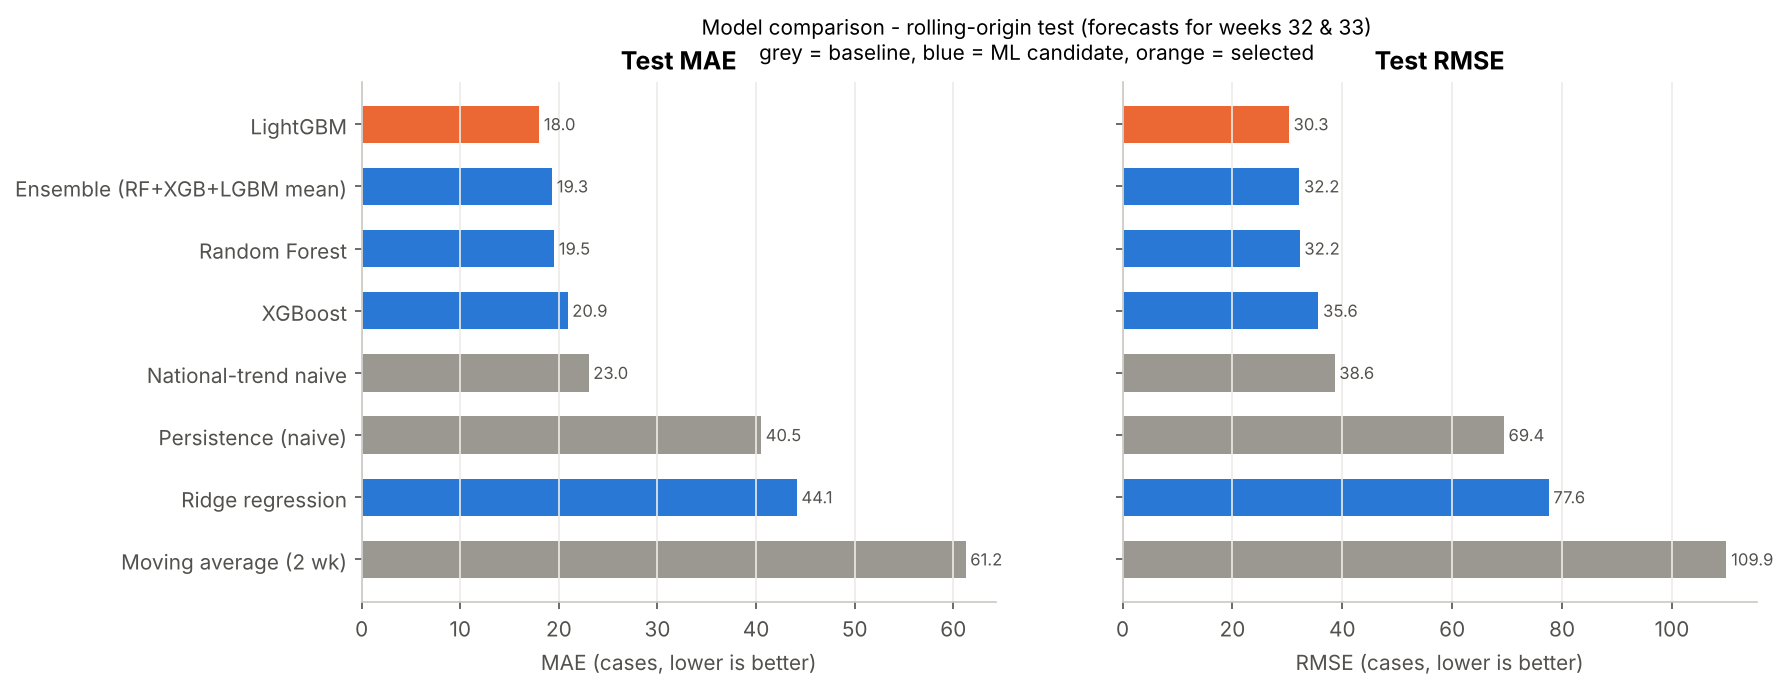

In [14]:
for f in ['08_model_comparison.png']:
    display(Image(filename=str(FIG / f)))

In [15]:
display(pd.read_csv(RES / "seed_stability.csv", header=[0,1], index_col=0))
display(pd.read_csv(RES / "sensitivity_as_printed.csv")[["model","MAE","RMSE","R2","Skill_vs_persistence_%"]])
display(pd.read_csv(RES / "test_metrics_per_week.csv").query("model in ['LightGBM','Persistence (naive)','National-trend naive']"))

MAE                       RMSE                    
                mean   std    min    max   mean   std    min    max
model                                                              
LightGBM       17.98  0.27  17.51  18.18  30.78  0.71  29.78  31.68
Random Forest  19.24  0.25  18.88  19.48  31.79  0.54  30.91  32.26
XGBoost        22.00  1.09  20.47  23.21  37.48  2.27  34.83  40.11

,model,MAE,RMSE,R2,Skill_vs_persistence_%
0,Persistence (naive),40.500,69.396,0.853,0.000
1,National-trend naive,23.012,38.593,0.955,43.181
2,Random Forest,22.158,36.421,0.960,45.288
3,XGBoost,16.880,28.303,0.976,58.321
4,LightGBM,19.506,33.240,0.966,51.837


,model,target_date,MAE,actual_total,forecast_total
2,LightGBM,2026-08-09,17.1,3865.0,3683.8
3,LightGBM,2026-08-16,18.9,2682.0,3068.0
6,National-trend naive,2026-08-09,20.9,3865.0,3372.3
7,National-trend naive,2026-08-16,25.2,2682.0,3247.7
8,Persistence (naive),2026-08-09,33.5,3865.0,4594.0
9,Persistence (naive),2026-08-16,47.5,2682.0,3865.0


**Interpretation**
* **LightGBM is selected** because it has the lowest *validation* MAE among the ML models (36.8). The test set was not used for the choice.
  On the untouched test weeks it is also the best model: MAE **18.0 cases** per division-week (WAPE 14.3%),
  R^2 = 0.97, a **56% lower MAE than persistence** and ~22% lower than the national-trend baseline (MAE 23.0).
  The summed national forecast is within ~10% of the actual national total, versus ~31% for persistence.
* The **national-trend naive baseline is strong** - much of the gain over persistence comes from knowing the epidemic is in decline.
  The ML models add a further, smaller improvement by learning division-specific behaviour (e.g. partial rebound after a sharp drop).
* Random Forest, XGBoost and the ensemble are close (MAE 19.3-20.9) - differences of 1-3 cases should not be over-interpreted with 52 test forecasts.
  Seed stability (5 seeds) confirms LightGBM's MAE varies by only ~0.3 cases.
* **Ridge regression fails** (validation MAE 178): with 52-78 training rows and highly collinear features it extrapolates growth
  aggressively for large divisions - a good illustration of why the linear model is only a benchmark here.
* The 2-week moving average is worse than persistence because, in a declining season, averaging with an older (higher) week lags the trend.
* **Sensitivity:** using the data exactly as printed (keeping weeks 24 and 26) gives the same ranking of ML over baselines; XGBoost becomes
  slightly better than LightGBM. The conclusion "tree models beat the baselines" is robust; the exact winner among tree models is not.

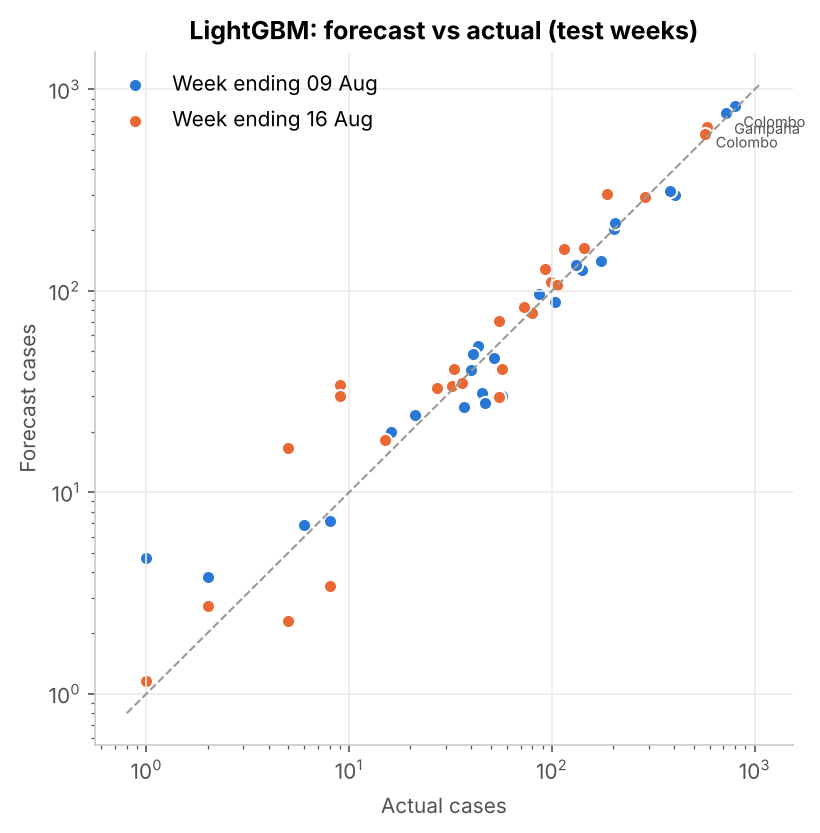

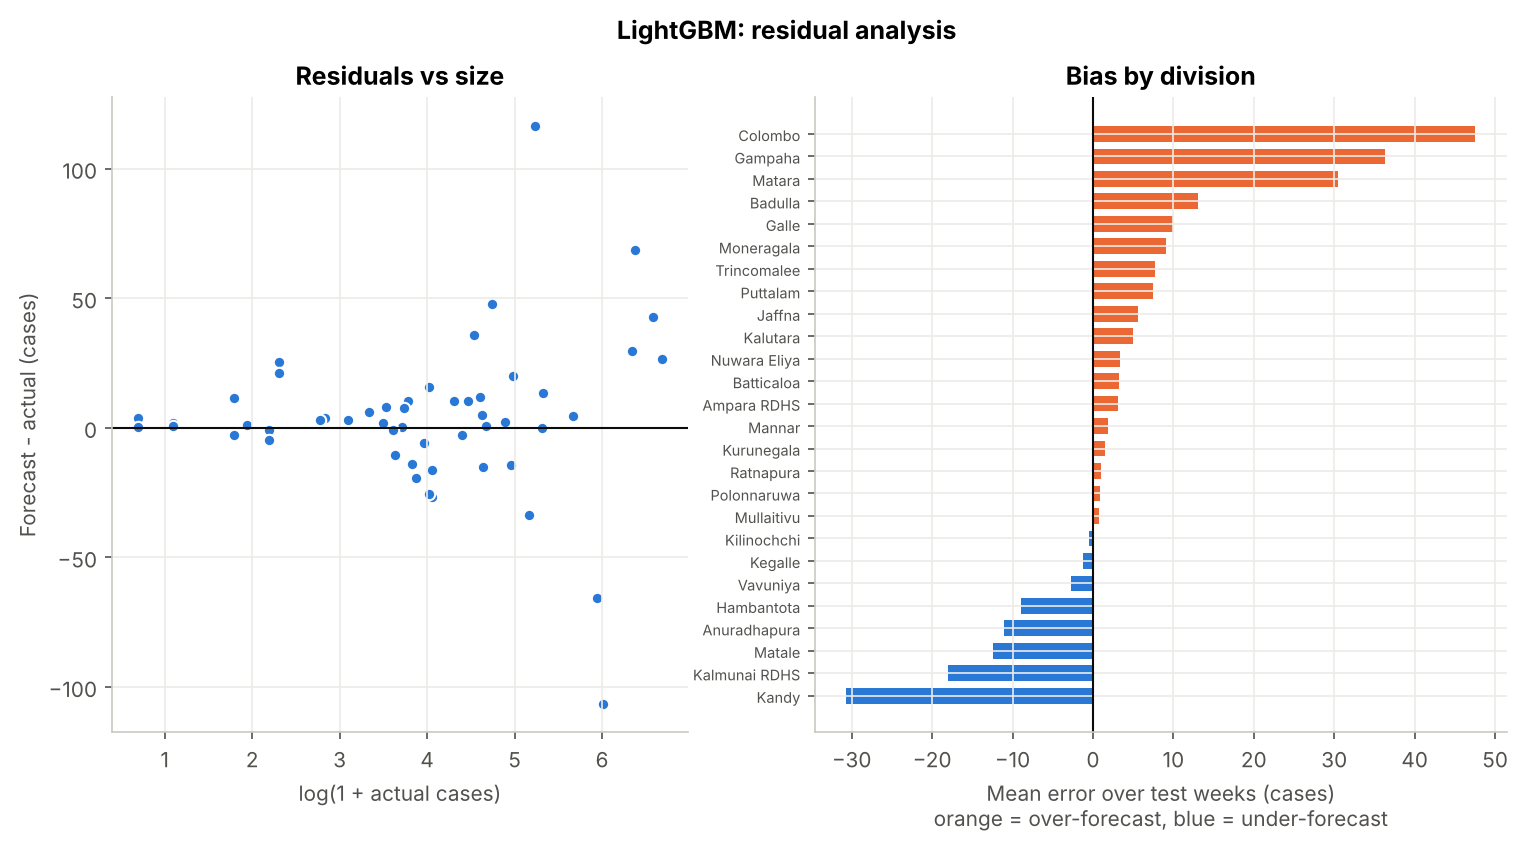

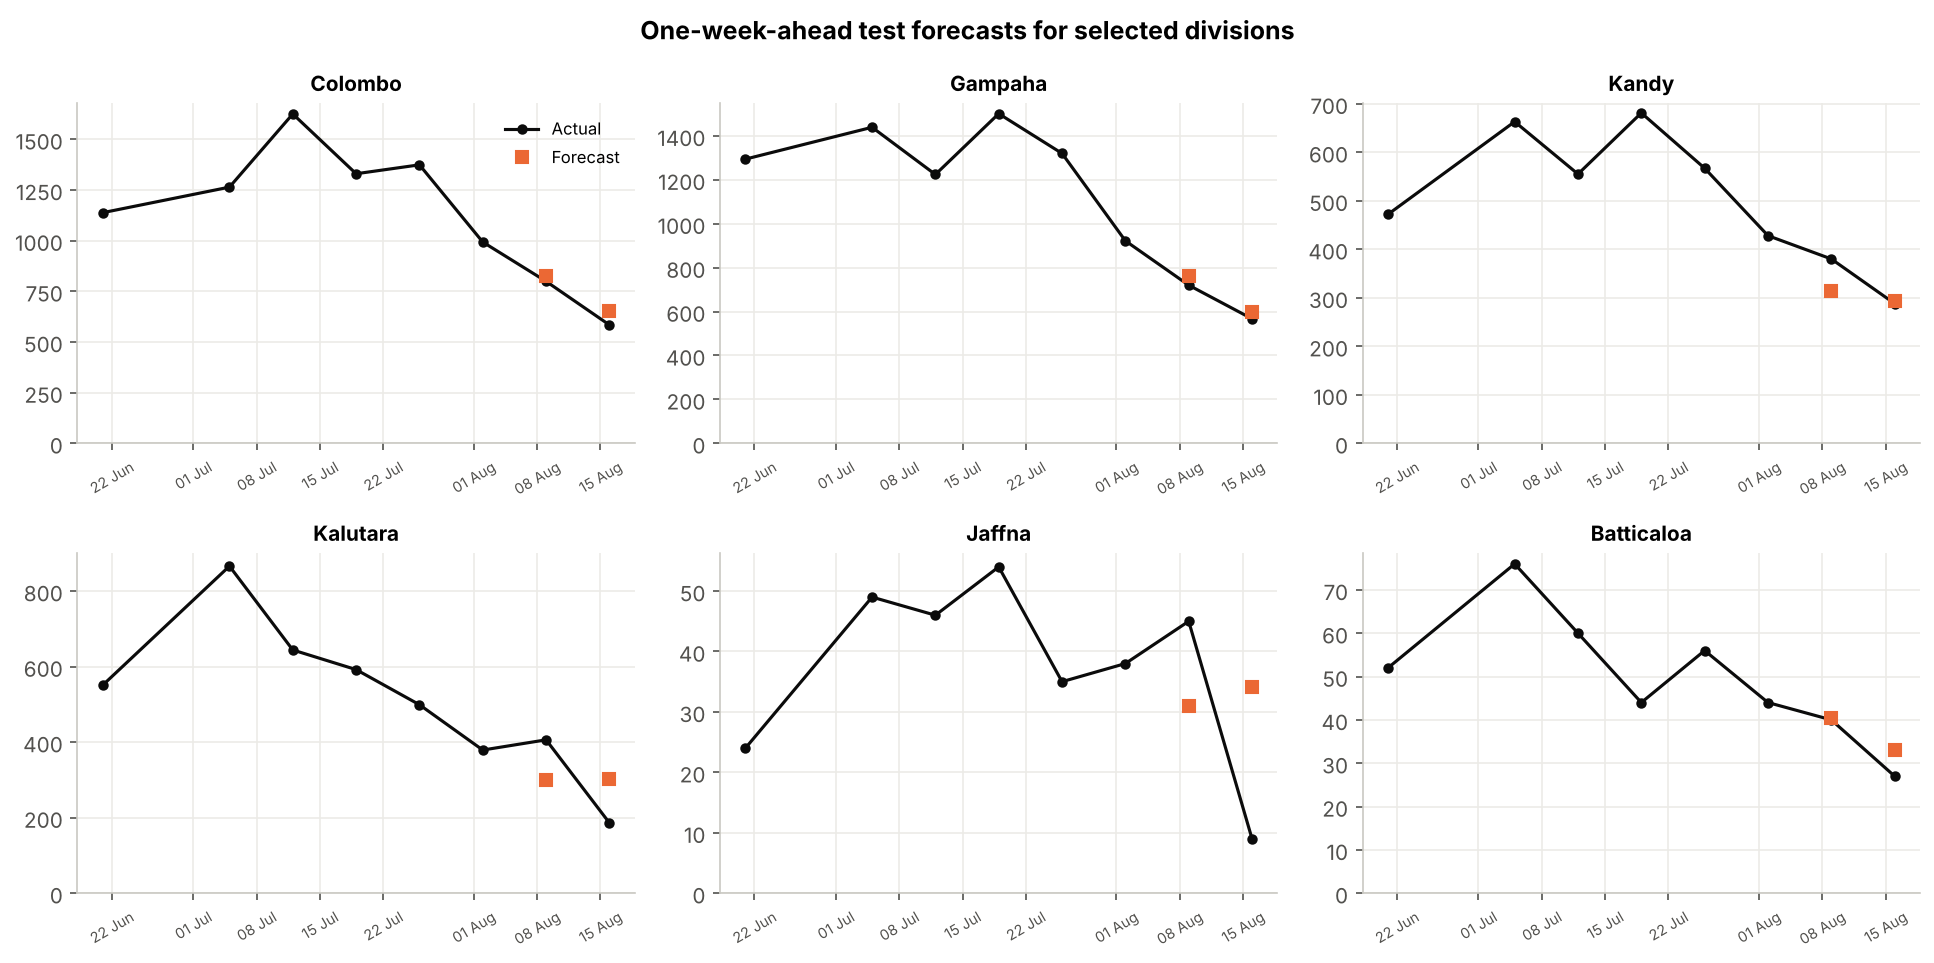

In [16]:
for f in ['09_predicted_vs_actual.png', '10_residuals.png', '11_division_forecasts.png']:
    display(Image(filename=str(FIG / f)))

Errors grow with division size (as expected for counts). LightGBM over-forecast Colombo, Gampaha and Matara in the test weeks:
those divisions fell faster than the model expected. The largest relative misses are small divisions with abrupt one-week
changes (e.g. Jaffna 45 -> 9, Polonnaruwa 47 -> 9), which no model using only past counts can anticipate.

## 8. Explainability - SHAP (global + local) and LIME (local)
The explained model is LightGBM trained on origins before 9 Aug, explaining its forecasts for the week ending 16 Aug.
**Units:** contributions are in *log-growth* units - +0.10 means about 10% more cases next week than otherwise predicted.

### 8.1 Global SHAP

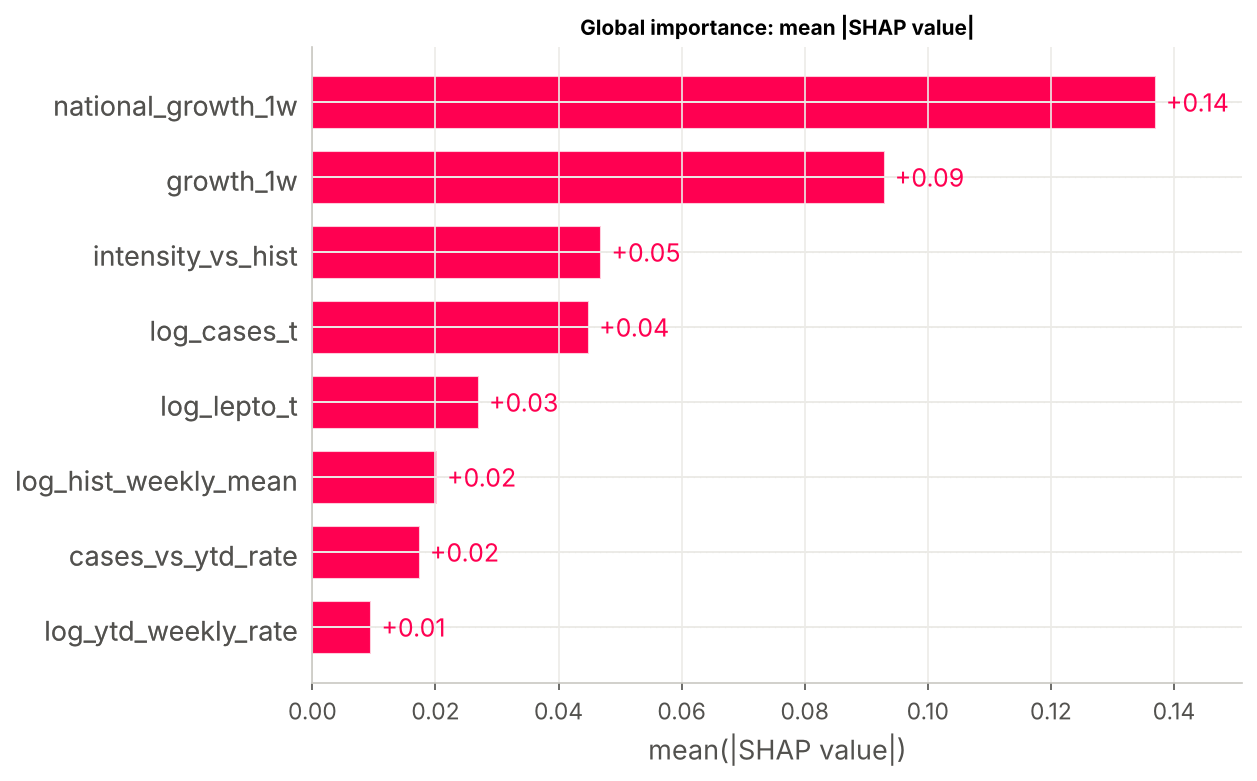

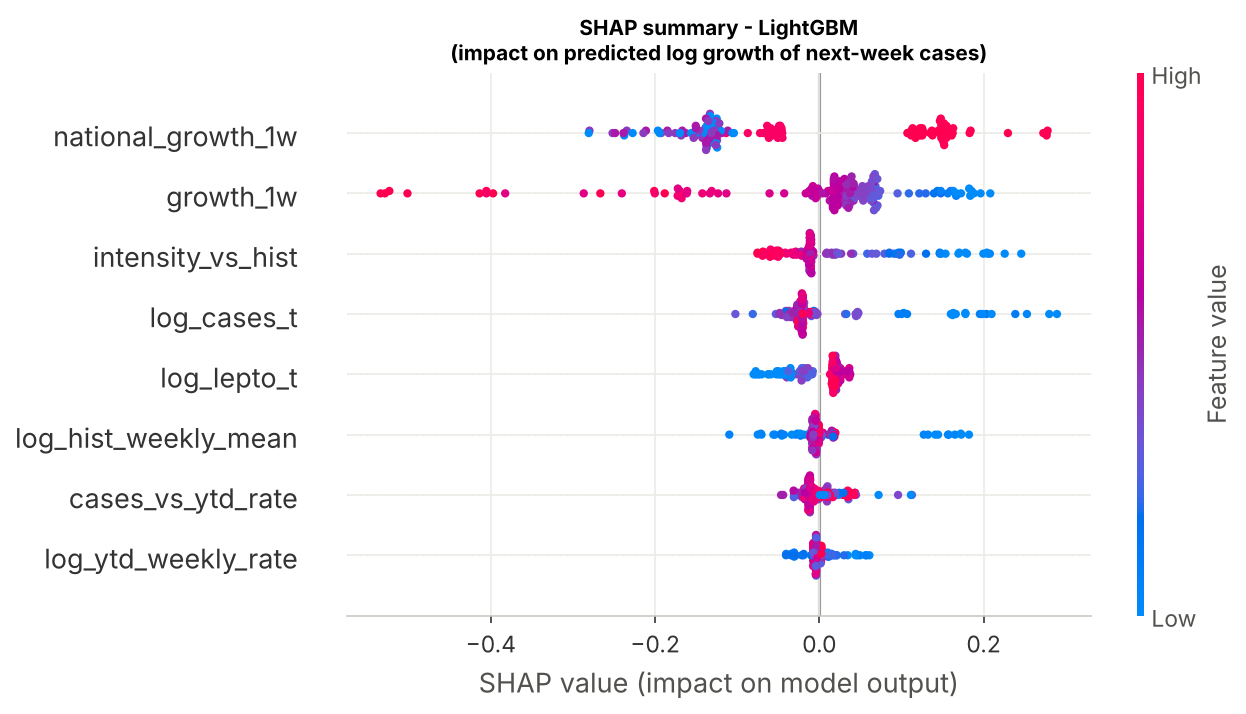

In [17]:
for f in ['13_shap_bar.png', '12_shap_beeswarm.png']:
    display(Image(filename=str(FIG / f)))

In [18]:
pd.read_csv(RES / 'shap_global_importance.csv')

,Unnamed: 0,mean_abs_shap
0,national_growth_1w,0.1371
1,growth_1w,0.0930
2,intensity_vs_hist,0.0470
3,log_cases_t,0.0450
4,log_lepto_t,0.0271
5,log_hist_weekly_mean,0.0203
6,cases_vs_ytd_rate,0.0175
7,log_ytd_weekly_rate,0.0096


* **`national_growth_1w`** (island-wide change last week) is the strongest driver: when the national total was falling,
  the model lowers every division's forecast. Note it takes only six distinct values in the data (one per week), so the
  model is effectively learning *which phase of the season* it is in - a signal from only six weeks, which may not transfer
  to a rising phase.
* **`growth_1w`** (the division's own change) has a **negative** relationship: a large rise last week pushes the forecast down
  and a large fall pushes it up - the model has learned **mean reversion** (week-to-week notification noise partly cancels out).
* **Size / intensity features** (`intensity_vs_hist`, `log_cases_t`): divisions that are already far above their historical
  weekly average tend to be forecast to fall more.
* `log_lepto_t` has a small positive effect; given it mostly proxies division size/wetness, it should not be read as a causal signal.

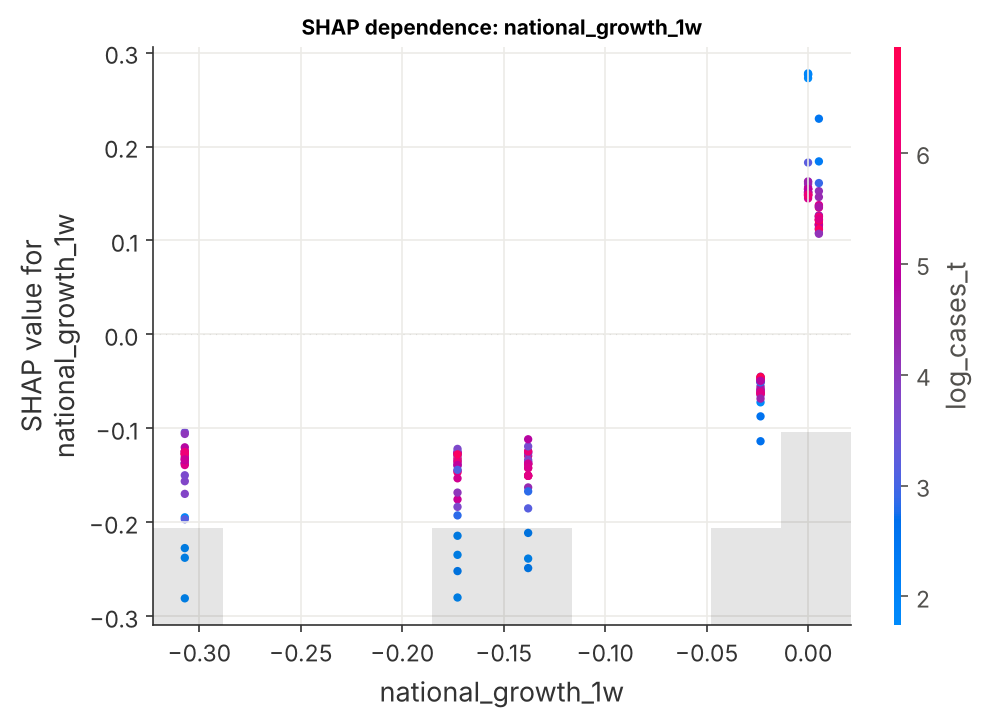

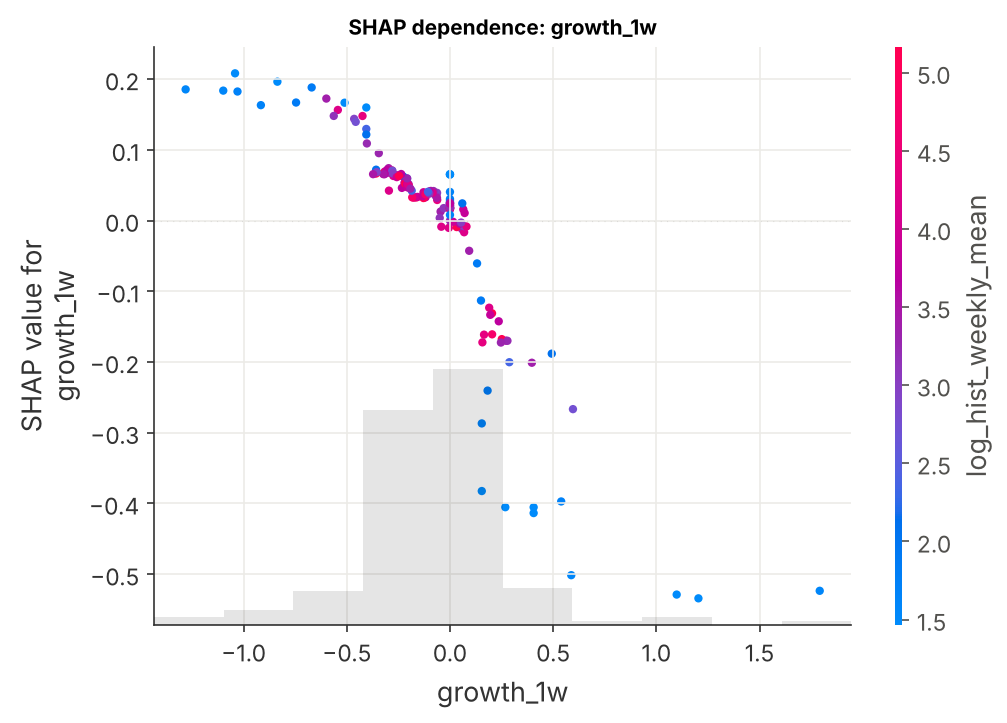

In [19]:
for f in ['14_shap_dependence_1_national_growth_1w.png', '14_shap_dependence_2_growth_1w.png']:
    display(Image(filename=str(FIG / f)))

### 8.2 Local explanation - Colombo, forecast for the week ending 16 Aug 2026 (SHAP waterfall and LIME)

In [20]:
loc = json.load(open(RES / "local_explanation_colombo.json"))
print(json.dumps({k: loc[k] for k in ["cases_this_week","predicted_cases","actual_cases","predicted_log_growth","shap_base_value"]}, indent=1))

{
 "cases_this_week": 799,
 "predicted_cases": 652.7,
 "actual_cases": 584,
 "predicted_log_growth": -0.2019,
 "shap_base_value": -0.0982
}


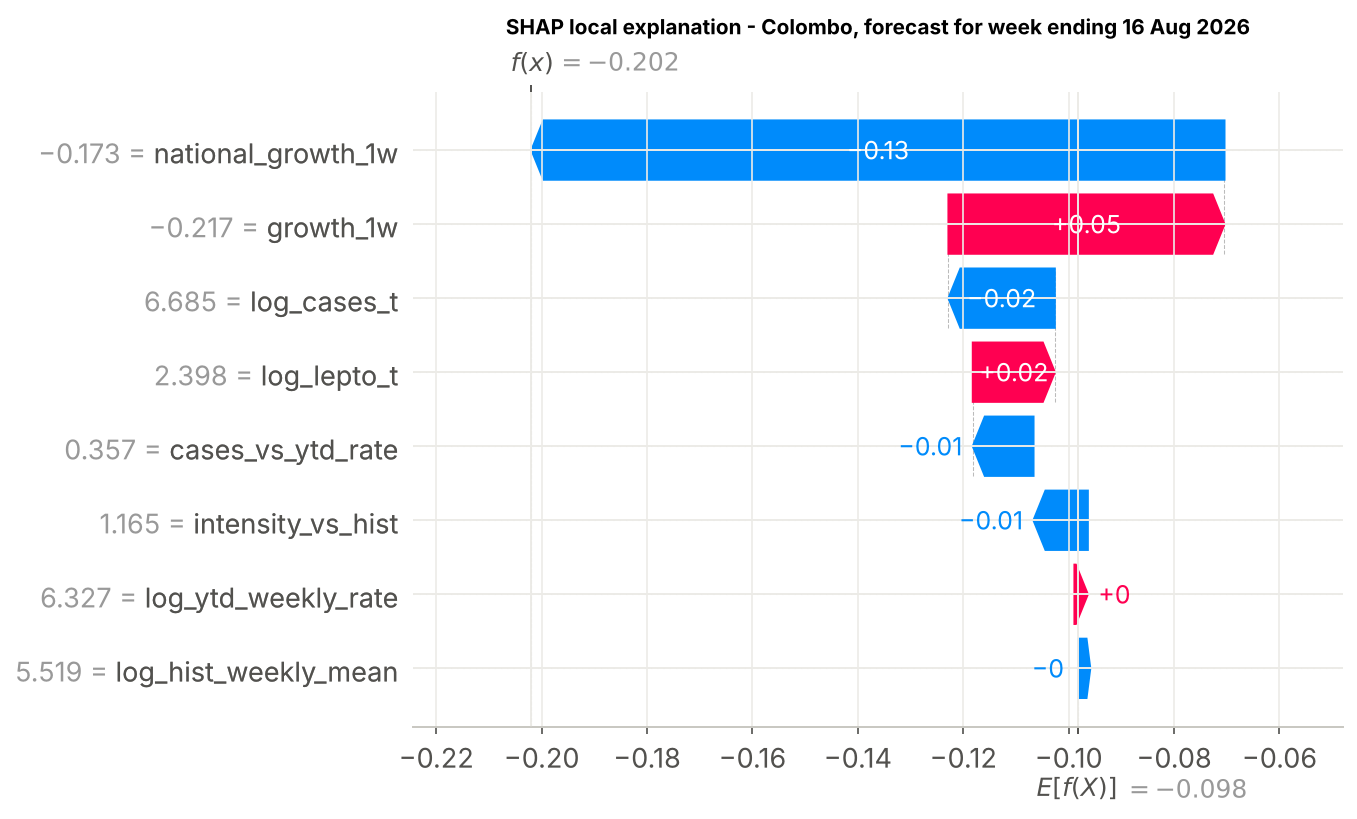

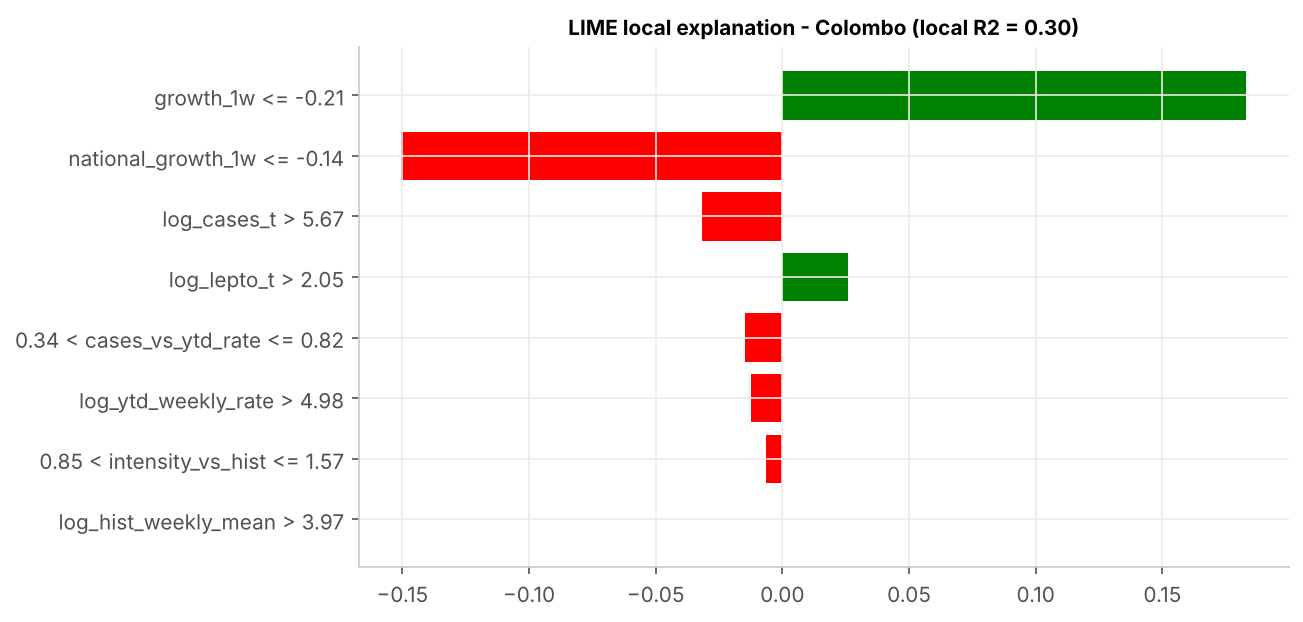

In [21]:
for f in ['15_shap_waterfall_colombo.png', '16_lime_colombo.png']:
    display(Image(filename=str(FIG / f)))

In [22]:
pd.DataFrame({"SHAP": loc["shap_contributions"]}).sort_values("SHAP")

,SHAP
national_growth_1w,-0.1315
log_cases_t,-0.0202
cases_vs_ytd_rate,-0.0115
intensity_vs_hist,-0.0103
log_hist_weekly_mean,-0.0007
log_ytd_weekly_rate,0.0025
log_lepto_t,0.0156
growth_1w,0.0524


In [23]:
pd.DataFrame(loc["lime_weights"], columns=["LIME condition", "weight"]).assign(local_R2=loc["lime_local_r2"])

,LIME condition,weight,local_R2
0,growth_1w <= -0.21,0.1832,0.305
1,national_growth_1w <= -0.14,-0.1505,0.305
2,log_cases_t > 5.67,-0.0316,0.305
3,log_lepto_t > 2.05,0.0260,0.305
4,0.34 < cases_vs_ytd_rate <= 0.82,-0.0147,0.305
5,log_ytd_weekly_rate > 4.98,-0.0123,0.305
6,0.85 < intensity_vs_hist <= 1.57,-0.0063,0.305
7,log_hist_weekly_mean > 3.97,-0.0001,0.305


Colombo notified **799** cases in the week ending 9 Aug. LightGBM forecast **~653** for the next week; the actual was **584**
(persistence would have said 799).

* **SHAP:** starting from the average predicted growth (about -0.10), the national decline (`national_growth_1w = -0.17`) pulls
  the forecast down by a further ~0.13; Colombo's own 19% drop the previous week (`growth_1w = -0.22`) pushes it *up* by ~0.05
  (mean reversion), and Colombo's large size pulls it down slightly. Net: about -18% -> ~653 cases.
* **LIME** fits a local linear surrogate around this case and agrees on the two main drivers and their directions
  (national decline -> down; recent drop in Colombo -> up). Its local R^2 is only ~0.3, so the surrogate is a rough approximation;
  where LIME and SHAP disagree on magnitudes, SHAP (exact for tree models) is the more reliable reading.
* **Domain sense:** following the national downturn after the south-west monsoon peak is plausible. The model still
  under-estimated how fast Colombo fell - the actual drop was 27%.

### 8.3 Limits of these explanations
* Explanations describe what the model learned from **six weeks of a single declining season** - not causes of dengue.
* Correlated features (size, YTD rate, historical mean) share credit somewhat arbitrarily.
* The model has no rainfall, temperature, vector-index or population data, so it cannot "know" about weather-driven changes.

## 9. Forward forecast, conclusions and limitations

In [24]:
fc = pd.read_csv(RES / "forecast_next_week.csv", parse_dates=["origin_date","target_date"])
print("Forecast for week ending", fc.target_date.max().date(), "| sum of divisions:", round(fc.forecast_cases.sum()), "cases")
fc.sort_values("forecast_cases", ascending=False).head(10)

Forecast for week ending 2026-08-23 | sum of divisions: 2124 cases


,place,origin_date,target_date,cases_t,persistence_forecast,forecast_cases
4,Colombo,2026-08-16,2026-08-23,584.0,584.0,449.5
6,Gampaha,2026-08-16,2026-08-23,567.0,567.0,445.7
11,Kandy,2026-08-16,2026-08-23,288.0,288.0,220.4
10,Kalutara,2026-08-16,2026-08-23,186.0,186.0,154.1
5,Galle,2026-08-16,2026-08-23,144.0,144.0,109.5
17,Matara,2026-08-16,2026-08-23,114.0,114.0,93.4
14,Kurunegala,2026-08-16,2026-08-23,106.0,106.0,85.0
12,Kegalle,2026-08-16,2026-08-23,99.0,99.0,81.3
23,Ratnapura,2026-08-16,2026-08-23,92.0,92.0,80.7
7,Hambantota,2026-08-16,2026-08-23,80.0,80.0,64.1


This is a genuine out-of-sample forecast for the week ending 23 Aug 2026; the actual figure is **not** in the dataset,
so it cannot be scored here. It can be checked later against the Weekly Epidemiological Report.

### Conclusions
* A LightGBM model on log-growth features forecasts next-week dengue notifications per RDHS division with
  MAE ~18 cases (WAPE ~14%), more than halving the error of persistence on the held-out weeks.
* Most of the benefit comes from tracking the national epidemic phase; ML adds a further ~20% over a simple national-trend rule.
* SHAP and LIME show the model relies on the national trend, mean reversion and division intensity - interpretable, plausible patterns.

### Limitations (see `docs/dataset_limitations.md`)
1. **Very short history:** 10 weekly reports (2026 weeks 24-33), of which 2 are unreliable -> 156 training/evaluation rows, 52 test forecasts.
   Results describe one declining phase of one season and may not hold at the start of an outbreak.
2. **Data issues:** week 24 division values appear misaligned; week 26 duplicates week 25 (and therefore 2026 YTD figures
   from week 26 onward include week 25 twice).
3. **Notified cases != infections:** reporting delays, holidays and testing behaviour affect the counts.
4. **No climate or entomology data:** rainfall and temperature drive dengue with a lag; they would be the first features to add.
5. **No population denominators:** cases are not converted to incidence rates.

### Next steps
Extend the series back several years from the Weekly Epidemiological Report archive, add lagged rainfall/temperature from the
Department of Meteorology, evaluate across multiple seasons (including outbreak onsets), and forecast 2-4 weeks ahead.